# Capstone project - Air passengers, start to finish

The course pipeline, on this series: explore it, decompose it, set the
benchmark floor, check what the floor leaves on the table, fit a model
through the framework, cross-validate, and read the result against the
floor.

**What is graded is the process, not the number.** A low MASE from one
holdout with no intervals scores worse than an honest analysis that
concludes the benchmark wins.

Full rules and report requirements: `brief.md`. Grading: `rubric.md`. This
notebook is the first deliverable; it should run top to bottom in under ten
minutes on Colab.

This notebook is a starter. You may swap in your own series or your own
framework - see "Your own data or method" in `brief.md`.

In [1]:
import sys

if "google.colab" in sys.modules:
    !git clone -q https://github.com/SDAIAAcademy/international-airpassengers-project.git /content/proj
    %cd /content/proj
    !pip install -q -e .

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from coursekit import plotting as P
from coursekit import scoring

P.use_course_style()

SEASON_LENGTH = 12
H = 12            # forecast horizon for cross-validation
H_REPORT = 24     # forecast horizon for the report

/content/proj
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Installing backend dependencies ... done
  Preparing editable metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 501.8/501.8 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 348.7/348.7 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 281.0/281.0 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.4/50.4 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.9/59.9 kB 1.8 MB/s eta 0:00:00
  Building editable for international-airpassengers-project (pyproject.toml) ... done


/content/proj/coursekit/plotting.py:599: SyntaxWarning: invalid escape sequence '\h'
  :math:`\hat{F}` whose characteristics do not change over time -- so that a
/content/proj/coursekit/plotting.py:676: SyntaxWarning: invalid escape sequence '\h'
  """Draw the h-step errors :math:`e_{t+h|t} = y_{t+h} - \hat{y}_{t+h|t}`.


In [2]:

# Install AutoGluon TimeSeries for reproducible execution
%pip install -q "autogluon.timeseries"


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.0/45.0 kB 471.0 kB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 274.4/274.4 kB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.7/90.7 kB 6.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 248.4/248.4 kB 10.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 112.3/112.3 kB 7.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 514.8/514.8 kB 8.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.8/80.8 kB 5.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 285.4/285.4 kB 17.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 864.0/864.0 kB 26.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 849.3/849.3 kB 26.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.0/72.0 kB 4.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

---
# 0. The data

Monthly international air passenger numbers, 1949-01 to 1960-12: 144
observations, no gaps. The Box & Jenkins classic (1970) — twelve years of
growth, and a year that does not repeat the same way twice.

Fetched from statsmodels' R-datasets on first run; no download step.

In [3]:
from statsmodels.datasets import get_rdataset

raw = get_rdataset("AirPassengers").data
t = raw["time"].astype(float).to_numpy()
years = np.floor(t).astype(int)
months = np.clip(np.round((t - years) * 12).astype(int) + 1, 1, 12)
df = pd.DataFrame({
    "unique_id": "Air passengers (Box & Jenkins)",
    "ds": pd.to_datetime(pd.Series(years).astype(str) + "-" +
                         pd.Series(months).astype(str).str.zfill(2) + "-01"),
    "y": raw["value"].astype(float),
}).sort_values("ds").reset_index(drop=True)
df.head()

,unique_id,ds,y
0,Air passengers (Box & Jenkins),1949-01-01,112.0
1,Air passengers (Box & Jenkins),1949-02-01,118.0
2,Air passengers (Box & Jenkins),1949-03-01,132.0
3,Air passengers (Box & Jenkins),1949-04-01,129.0
4,Air passengers (Box & Jenkins),1949-05-01,121.0


In [4]:
# TODO:

# Check the number of observations
n_obs = len(df)

# Find the first and last dates
range_ = (df["ds"].min(), df["ds"].max())

# Generate all expected monthly dates
expected_months = pd.date_range(
    start=range_[0],
    end=range_[1],
    freq="MS"
)

# Count missing months
n_gaps = len(expected_months.difference(df["ds"]))

print(f"{n_obs} months, {range_[0].date()} to {range_[1].date()}, {n_gaps} gaps")


144 months, 1949-01-01 to 1960-12-01, 0 gaps


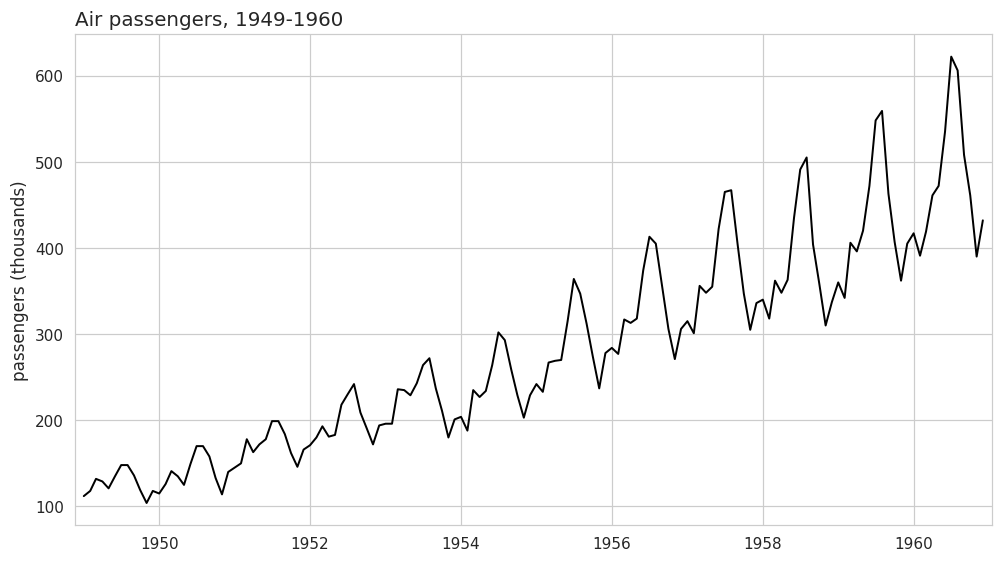

In [5]:
P.plot_series(df, title="Air passengers, 1949-1960",
              ylabel="passengers (thousands)", xlabel="")
plt.show()

International air passenger numbers increased steadily from 1949 to 1960, reflecting strong long-term growth in air travel. A recurring yearly pattern is visible, with higher peaks and deeper seasonal swings as passenger numbers grow, suggesting that both trend and seasonality are important for forecasting.

**First read.** Before any model, write two sentences that describe this
series in plain language - the kind a non-forecaster could repeat. (Trend?
Seasonality? What happens to the swings as the level grows? Cycle?) These two
sentences belong at the top of your report.

---
# 1. Exploration and shape

The Day 1 toolkit, in order. Every chart should carry its claim: a title that
says what it shows, not just "series".

**1.1 Decompose.** STL, additive, period 12. Read all three panels: which
component does the work, and what does the remainder look like?

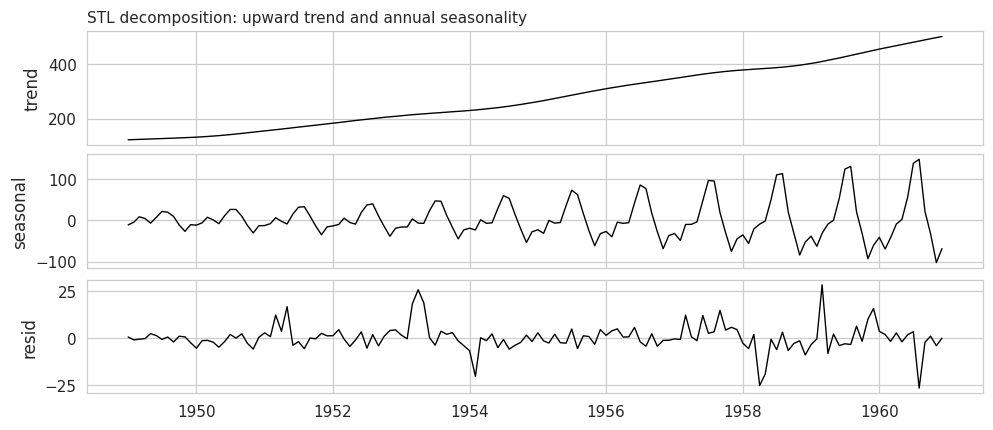

In [6]:
# TODO:

from statsmodels.tsa.seasonal import STL

# Prepare the monthly time series
series = df.set_index("ds")["y"]

# Apply STL decomposition
stl = STL(series, period=SEASON_LENGTH, robust=True)
result = stl.fit()

# Store the three components
dcmp = pd.DataFrame({
    "ds": df["ds"],
    "trend": result.trend.to_numpy(),
    "seasonal": result.seasonal.to_numpy(),
    "resid": result.resid.to_numpy()
})

# Plot the decomposition
P.decomposition_plot(
    dcmp,
    cols=["trend", "seasonal", "resid"],
    title="STL decomposition: upward trend and annual seasonality",
    x="ds"
)

plt.show()


**STL Decomposition Analysis**

The trend component shows a clear and sustained increase in international passenger numbers from 1949 to 1960, indicating strong long-term growth.

The seasonal component reveals a recurring annual pattern, with larger seasonal fluctuations as passenger numbers increase. This suggests that seasonality becomes more pronounced in absolute terms over time.

The residual component fluctuates mostly around zero, with a few noticeable positive and negative spikes. This indicates that the trend and seasonal components explain much of the variation, although some irregular changes remain unexplained.

Overall, the decomposition suggests that forecasting models should account for both the upward trend and annual seasonality.

**1.2 Trend and seasonal strength.** The two numbers from Day 1, computed
the same way (textbook formulas on the STL components). State what they
imply for model choice.

In [7]:
# TODO:

# Extract STL components
trend = dcmp["trend"]
seasonal = dcmp["seasonal"]
residual = dcmp["resid"]

# Calculate trend strength
trend_strength = max(
    0,
    1 - np.var(residual) / np.var(trend + residual)
)

# Calculate seasonal strength
seasonal_strength = max(
    0,
    1 - np.var(residual) / np.var(seasonal + residual)
)

# Display results
print(f"trend strength: {trend_strength:.2f}")
print(f"seasonal strength: {seasonal_strength:.2f}")


trend strength: 1.00
seasonal strength: 0.98


**Trend and Seasonal Strength Analysis**

The STL decomposition produced a trend strength of 1.00 and a seasonal strength of 0.98, indicating that both components are extremely strong.

These results confirm that the series exhibits substantial long-term growth and a highly consistent annual seasonal pattern. Therefore, forecasting models that account for both trend and seasonality, such as AutoETS and AutoARIMA, are suitable candidates for evaluation against the Seasonal Naive benchmark.

**1.3 Autocorrelation.** The ACF of the raw series. What is at lag 12?
At 24? What does that tell you before you fit anything?

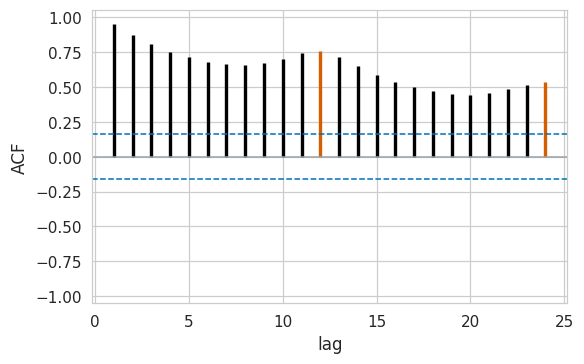

In [8]:
# TODO:

# Plot autocorrelation of the original time series
P.acf_plot(
    df["y"],
    nlags=24,
    highlight_every=SEASON_LENGTH
)

plt.show()


**Autocorrelation (ACF) Analysis**

The ACF shows strong positive autocorrelation at short lags, with a gradual decline as the lag increases. This indicates that passenger numbers are strongly related to their previous values and reflects the persistent upward trend.

The notable positive correlations at lag 12 (approximately 0.76) and lag 24 (approximately 0.53) are consistent with a recurring annual seasonal pattern. However, these correlations are also influenced by the long-term trend.

Overall, the ACF supports the need for forecasting models that account for both trend and annual seasonality, while the slow decay suggests that the original series is non-stationary.

---
# 2. The floor

The seasonal naive is the first model you fit on any series - not as a
formality, as the thing everything else has to beat. Fit it, check what it
leaves on the table, and give it an honest interval.

In [9]:
from statsforecast import StatsForecast
from statsforecast.models import SeasonalNaive

floor_sf = StatsForecast(models=[SeasonalNaive(season_length=SEASON_LENGTH)],
                         freq="MS", n_jobs=1)
floor_fc = floor_sf.forecast(df=df, h=H_REPORT, level=scoring.LEVELS)
floor_fc.head()

,unique_id,ds,SeasonalNaive,SeasonalNaive-lo-20,SeasonalNaive-lo-40,SeasonalNaive-lo-60,SeasonalNaive-lo-80,SeasonalNaive-lo-95,SeasonalNaive-hi-20,SeasonalNaive-hi-40,SeasonalNaive-hi-60,SeasonalNaive-hi-80,SeasonalNaive-hi-95
0,Air passengers (Box & Jenkins),1961-01-01,417.0,407.799511,397.956005,386.435898,370.4595,345.822448,426.200489,436.043995,447.564102,463.5405,488.177552
1,Air passengers (Box & Jenkins),1961-02-01,391.0,381.799511,371.956005,360.435898,344.4595,319.822448,400.200489,410.043995,421.564102,437.5405,462.177552
2,Air passengers (Box & Jenkins),1961-03-01,419.0,409.799511,399.956005,388.435898,372.4595,347.822448,428.200489,438.043995,449.564102,465.5405,490.177552
3,Air passengers (Box & Jenkins),1961-04-01,461.0,451.799511,441.956005,430.435898,414.4595,389.822448,470.200489,480.043995,491.564102,507.5405,532.177552
4,Air passengers (Box & Jenkins),1961-05-01,472.0,462.799511,452.956005,441.435898,425.4595,400.822448,481.200489,491.043995,502.564102,518.5405,543.177552


In [10]:

from statsforecast.models import Naive

# Fit a second benchmark model
naive_sf = StatsForecast(
    models=[Naive()],
    freq="MS",
    n_jobs=1
)

# Forecast the next 24 months
naive_fc = naive_sf.forecast(
    df=df,
    h=H_REPORT,
    level=scoring.LEVELS
)

naive_fc.head()


,unique_id,ds,Naive,Naive-lo-20,Naive-lo-40,Naive-lo-60,Naive-lo-80,Naive-lo-95,Naive-hi-20,Naive-hi-40,Naive-hi-60,Naive-hi-80,Naive-hi-95
0,Air passengers (Box & Jenkins),1961-01-01,432.0,423.459566,414.322245,403.628605,388.798374,365.928814,440.540434,449.677755,460.371395,475.201626,498.071186
1,Air passengers (Box & Jenkins),1961-02-01,432.0,419.922002,406.999879,391.876788,370.903674,338.561233,444.077998,457.000121,472.123212,493.096326,525.438767
2,Air passengers (Box & Jenkins),1961-03-01,432.0,417.207534,401.381230,382.859302,357.172589,317.561350,446.792466,462.618770,481.140698,506.827411,546.438650
3,Air passengers (Box & Jenkins),1961-04-01,432.0,414.919132,396.644490,375.257210,345.596748,299.857629,449.080868,467.355510,488.742790,518.403252,564.142371
4,Air passengers (Box & Jenkins),1961-05-01,432.0,412.903009,392.471338,368.559632,335.398227,284.260338,451.096991,471.528662,495.440368,528.601773,579.739662


In [11]:

from statsforecast.models import Naive, SeasonalNaive

# Evaluate both benchmarks using historical data
benchmark_sf = StatsForecast(
    models=[
        Naive(),
        SeasonalNaive(season_length=SEASON_LENGTH)
    ],
    freq="MS",
    n_jobs=1
)

# Rolling-origin cross-validation
benchmark_cv = benchmark_sf.cross_validation(
    df=df,
    h=H,
    step_size=H,
    n_windows=8,
    level=[80]
)

# Calculate empirical 80% coverage
for model in ["Naive", "SeasonalNaive"]:
    lower = benchmark_cv[f"{model}-lo-80"]
    upper = benchmark_cv[f"{model}-hi-80"]
    actual = benchmark_cv["y"]

    inside = (actual >= lower) & (actual <= upper)
    coverage = inside.mean() * 100

    print(f"{model} - 80% Coverage: {coverage:.2f}%")


Naive - 80% Coverage: 68.75%
SeasonalNaive - 80% Coverage: 51.04%


**Benchmark Comparison and 80% Coverage Analysis**

Two benchmark models were evaluated: Naive and Seasonal Naive. The Naive model repeats the latest observed value, while Seasonal Naive repeats the corresponding value from the previous year.

Using eight rolling-origin validation windows with a 12-month forecasting horizon, the empirical 80% coverage was 68.75% for Naive and 51.04% for Seasonal Naive.

Both models fall below the nominal 80% coverage level, indicating that their prediction intervals are insufficiently calibrated and fail to capture a substantial proportion of actual observations. Seasonal Naive shows particularly poor interval coverage despite capturing the annual seasonal pattern.

These results highlight the need to evaluate point forecast accuracy and probabilistic forecast quality separately before selecting a final model.

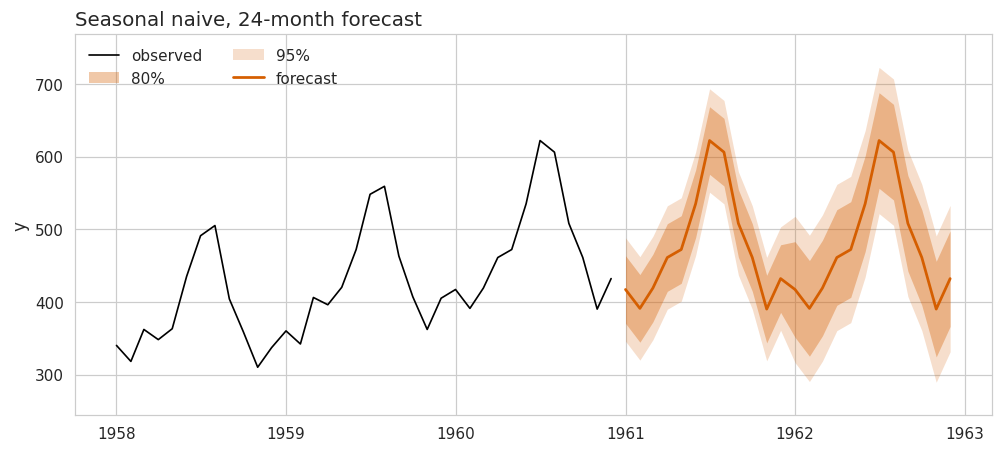

In [12]:
P.fan_chart(df, floor_fc.rename(columns={
            "SeasonalNaive": "mean",
            "SeasonalNaive-lo-20": "lo-20",
            "SeasonalNaive-lo-40": "lo-40",
            "SeasonalNaive-lo-60": "lo-60",
            "SeasonalNaive-lo-80": "lo-80",
            "SeasonalNaive-lo-95": "lo-95",
            "SeasonalNaive-hi-20": "hi-20",
            "SeasonalNaive-hi-40": "hi-40",
            "SeasonalNaive-hi-60": "hi-60",
            "SeasonalNaive-hi-80": "hi-80",
            "SeasonalNaive-hi-95": "hi-95",
            "ds": "ds"}),
            title="Seasonal naive, 24-month forecast",
            history_tail=36, levels=(80, 95))
plt.show()

**Seasonal Naive Forecast Analysis**

The Seasonal Naive model produces a 24-month forecast by repeating the seasonal pattern observed in the final historical year. The forecasts preserve the recurring annual peaks and troughs but do not account for the long-term upward trend in passenger numbers.

The 80% and 95% prediction intervals represent uncertainty around the forecasts, with wider intervals at longer forecast horizons. However, their reliability must be evaluated through historical coverage testing rather than visual inspection alone.

**2.1 What is left on the table.** The floor's in-sample residuals are
``y_t - y_{t-12}`` over the series. Plot them, then their ACF (24 lags). Is
there a trend left? Correlation at the low lags? At 12? If it is not white
noise, what structure is it, and which kind of model eats that structure?

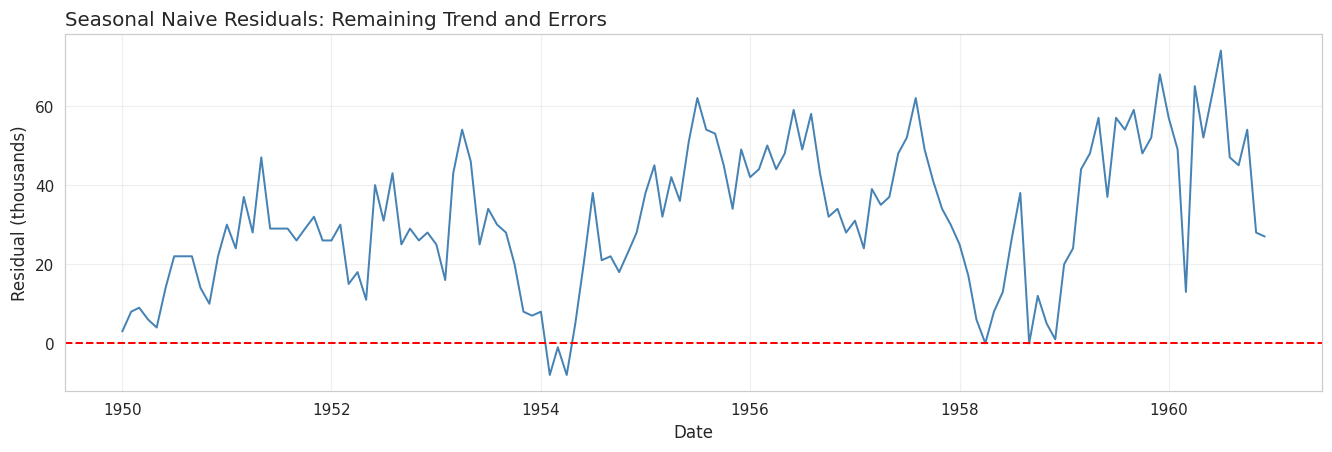

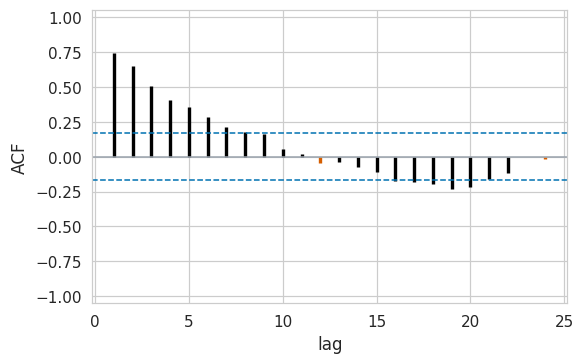

In [13]:
# TODO:

# Calculate Seasonal Naive residuals
resid_floor = df["y"] - df["y"].shift(SEASON_LENGTH)

# Remove the first 12 missing residuals
resid_floor = resid_floor.dropna()

# Plot residuals over time
plt.figure(figsize=(12, 4))
plt.plot(
    df["ds"].iloc[SEASON_LENGTH:],
    resid_floor,
    color="steelblue"
)
plt.axhline(0, color="red", linestyle="--")

plt.title("Seasonal Naive Residuals: Remaining Trend and Errors")
plt.xlabel("Date")
plt.ylabel("Residual (thousands)")
plt.grid(alpha=0.3)
plt.show()

# Plot residual autocorrelation
P.acf_plot(
    resid_floor,
    nlags=24,
    highlight_every=SEASON_LENGTH
)
plt.show()


**Seasonal Naive Residual Analysis**

The Seasonal Naive residuals are predominantly positive, indicating that the model systematically underestimates passenger numbers as air travel grows. The residuals also exhibit periods of persistent positive errors rather than fluctuating randomly around zero.

The residual ACF shows strong positive autocorrelation at short lags, with a lag-1 correlation of approximately 0.74. In contrast, the correlation at lag 12 is close to zero, suggesting that the seasonal differencing has removed much of the annual dependence.

Overall, the residuals are not white noise, indicating that the Seasonal Naive model leaves useful temporal structure unexplained. Models that explicitly account for trend and short-term dynamics, such as AutoETS or AutoARIMA, may improve forecasting performance.

---
# 3. Your model: the framework

AutoGluon fits a zoo of models behind one call - every model in the zoo
below is a model you have met in this course. The install is large, so this
runs on Colab.

> Every cell in this section is **skip-guarded**: without `autogluon`
> installed it prints why and moves on, so the rest of the notebook still
> runs.

In [14]:
import importlib.util

HAS_AG = importlib.util.find_spec("autogluon") is not None
if not HAS_AG:
    print("autogluon is not installed. On Colab, run this and re-run the cell:")
    print("    !pip install -q 'autogluon.timeseries'")
    print("\n(Takes a few minutes. A runtime reset wipes it.)")
else:
    print("autogluon is available")

autogluon is available


**3.1 The data conversion stays visible.** AutoGluon has its own
frame, its own column names, its own fit loop and its own leaderboard.
Writing it out by hand once is the point - the gap between two APIs doing
the same job is the thing to notice.

| | this course | AutoGluon |
|---|---|---|
| id column | `unique_id` | `item_id` |
| time column | `ds` | `timestamp` |
| value column | `y` | `target` (nameable) |
| frame | `pd.DataFrame` | `TimeSeriesDataFrame` |

In [15]:
if HAS_AG:
    from autogluon.timeseries import TimeSeriesDataFrame, TimeSeriesPredictor

    # Long format to AutoGluon's long format: the same three columns, renamed.
    ag_long = df.rename(columns={"unique_id": "item_id", "ds": "timestamp"})
    tsdf = TimeSeriesDataFrame.from_data_frame(
        ag_long, id_column="item_id", timestamp_column="timestamp")

    # One 12-month holdout, cut the way AutoGluon expects.
    ag_train = tsdf.slice_by_timestep(None, -12)

    print(tsdf.head(3))
    print(f"\nfull: {len(tsdf)} rows   train: {len(ag_train)} rows")

                                               y
item_id                        timestamp        
Air passengers (Box & Jenkins) 1949-01-01  112.0
                               1949-02-01  118.0
                               1949-03-01  132.0

full: 144 rows   train: 132 rows


In [16]:
if HAS_AG:
    # Local models only - the same zoo this course taught, nothing neural.
    ZOO = {"Naive": {}, "SeasonalNaive": {}, "AutoETS": {},
           "AutoARIMA": {}, "Theta": {}}

    predictor = TimeSeriesPredictor(
        prediction_length=12, target="y", eval_metric="MASE",
        freq="MS", verbosity=1)
    predictor.fit(ag_train, hyperparameters=ZOO, time_limit=120)

In [17]:
# TODO:

# Evaluate models on the held-out 12 months
leaderboard = predictor.leaderboard(tsdf)

# Display all available results
display(leaderboard)


,model,score_test,score_val,pred_time_test,pred_time_val,fit_time_marginal,fit_order
0,AutoARIMA,-0.608073,-1.575987,0.121020,0.107377,0.014088,5
1,Theta,-0.875371,-1.633923,0.013655,0.011869,0.013462,3
2,WeightedEnsemble,-0.929514,-1.535792,0.222839,0.245828,0.239051,6
3,AutoETS,-1.169539,-1.554323,0.100485,0.137003,0.013309,4
4,SeasonalNaive,-1.570881,-1.656513,0.007762,0.006967,0.012537,2
5,Naive,-2.495895,-3.196371,0.007891,0.007432,0.017791,1


In [18]:

from importlib.metadata import version

print("AutoGluon TimeSeries:", version("autogluon.timeseries"))
print("StatsForecast:", version("statsforecast"))
print("StatsModels:", version("statsmodels"))


AutoGluon TimeSeries: 1.6.3
StatsForecast: 2.0.3
StatsModels: 0.15.0


**AutoGluon Leaderboard Analysis**

AutoGluon evaluated five forecasting models and generated a WeightedEnsemble. The evaluation scores are reported as negative MASE values, where values closer to zero indicate better forecasting performance.

On the 12-month held-out test period, AutoARIMA achieved the lowest MASE of 0.6081, outperforming the Seasonal Naive benchmark (1.5709) and AutoETS (1.1695). However, the internal validation ranking differed, with WeightedEnsemble achieving a slightly better validation score than AutoARIMA.

The leaderboard's internal ranking is based on limited validation rather than the required eight rolling-origin windows, so it cannot establish which model performs best consistently across time.

Additionally, Theta encountered a forecasting failure and used Seasonal Naive as a fallback, so its result should be interpreted cautiously.

Based on its test performance and ability to model temporal dynamics, AutoARIMA is selected as the candidate for further evaluation through rolling-origin cross-validation.

**3.2 Read what it handed back.** What is the *sign* of `score_val`, and
what does the answer to "how many windows" mean for how much you should
trust this ranking? It decides what the next section does with this table.
And: does the shortlist agree with the shape you read in section 1?

---
# 4. The harness

The framework's ranking came from one internal split. One holdout is not a
ranking. So the shortlist goes through the rolling-origin harness: eight
origins, twelve months each, the whole distribution scored - and the floor
stays in the table.

In [19]:
sf_cv = StatsForecast(
    models=[SeasonalNaive(season_length=SEASON_LENGTH)],
    freq="MS", n_jobs=1)
cv = sf_cv.cross_validation(df=df, h=H, step_size=H, n_windows=8,
                            level=scoring.LEVELS)
cv.head()

,unique_id,ds,cutoff,y,SeasonalNaive,SeasonalNaive-lo-20,SeasonalNaive-lo-40,SeasonalNaive-lo-60,SeasonalNaive-lo-80,SeasonalNaive-lo-95,SeasonalNaive-hi-20,SeasonalNaive-hi-40,SeasonalNaive-hi-60,SeasonalNaive-hi-80,SeasonalNaive-hi-95
0,Air passengers (Box & Jenkins),1953-01-01,1952-12-01,196.0,171.0,164.48674,157.518271,149.362895,138.052796,120.6116,177.51326,184.481729,192.637105,203.947204,221.3884
1,Air passengers (Box & Jenkins),1953-02-01,1952-12-01,196.0,180.0,173.48674,166.518271,158.362895,147.052796,129.6116,186.51326,193.481729,201.637105,212.947204,230.3884
2,Air passengers (Box & Jenkins),1953-03-01,1952-12-01,236.0,193.0,186.48674,179.518271,171.362895,160.052796,142.6116,199.51326,206.481729,214.637105,225.947204,243.3884
3,Air passengers (Box & Jenkins),1953-04-01,1952-12-01,235.0,181.0,174.48674,167.518271,159.362895,148.052796,130.6116,187.51326,194.481729,202.637105,213.947204,231.3884
4,Air passengers (Box & Jenkins),1953-05-01,1952-12-01,229.0,183.0,176.48674,169.518271,161.362895,150.052796,132.6116,189.51326,196.481729,204.637105,215.947204,233.3884


In [20]:
# TODO:

from statsforecast.models import AutoARIMA

# Selected model from AutoGluon leaderboard
MY_MODEL = AutoARIMA(season_length=SEASON_LENGTH)
MY_NAME = "AutoARIMA"

# Create the forecasting model
mysf = StatsForecast(
    models=[MY_MODEL],
    freq="MS",
    n_jobs=1
)

# Evaluate on the same 8 rolling-origin windows
mycv = mysf.cross_validation(
    df=df,
    h=H,
    step_size=H,
    n_windows=8,
    level=scoring.LEVELS
)

# Inspect the results
mycv.head()


,unique_id,ds,cutoff,y,AutoARIMA,AutoARIMA-lo-95,AutoARIMA-lo-80,AutoARIMA-lo-60,AutoARIMA-lo-40,AutoARIMA-lo-20,AutoARIMA-hi-20,AutoARIMA-hi-40,AutoARIMA-hi-60,AutoARIMA-hi-80,AutoARIMA-hi-95
0,Air passengers (Box & Jenkins),1953-01-01,1952-12-01,196.0,200.033960,186.129327,190.942209,194.063221,196.313689,198.236632,201.831289,203.754231,206.004700,209.125712,213.938594
1,Air passengers (Box & Jenkins),1953-02-01,1952-12-01,196.0,205.951260,191.099431,196.240171,199.573789,201.977561,204.031496,207.871024,209.924959,212.328732,215.662349,220.803089
2,Air passengers (Box & Jenkins),1953-03-01,1952-12-01,236.0,228.492818,210.220348,216.545092,220.646501,223.603906,226.130899,230.854738,233.381731,236.339136,240.440545,246.765289
3,Air passengers (Box & Jenkins),1953-04-01,1952-12-01,235.0,214.413179,194.752951,201.558047,205.970950,209.152963,211.871877,216.954482,219.673395,222.855409,227.268312,234.073408
4,Air passengers (Box & Jenkins),1953-05-01,1952-12-01,229.0,220.835055,199.055069,206.593888,211.482588,215.007685,218.019750,223.650360,226.662425,230.187522,235.076222,242.615041


In [21]:

# Score both models using the official course harness
floor_scores = scoring.score_cv(
    cv, "SeasonalNaive", df
)

arima_scores = scoring.score_cv(
    mycv, "AutoARIMA", df
)

# Build the final comparison table
RESULTS = pd.DataFrame.from_dict(
    {
        "SeasonalNaive": floor_scores,
        "AutoARIMA": arima_scores
    },
    orient="index"
)

RESULTS.index.name = "Model"

# Display results
display(RESULTS.round(4))


,mase,rmsse,crps,coverage_80,mase_min,mase_max
Model,,,,,,
SeasonalNaive,1.3133,1.2456,0.0616,0.5104,0.4116,1.9587
AutoARIMA,0.6472,0.6833,0.0339,0.6979,0.3301,1.5938


**Rolling-Origin Cross-Validation Analysis**

The eight-window rolling-origin evaluation confirms that AutoARIMA outperforms the Seasonal Naive benchmark in both point forecast accuracy and probabilistic forecasting quality.

AutoARIMA achieved a MASE of 0.6472 compared with 1.3133 for Seasonal Naive, representing approximately a 50.7% reduction in scaled forecast error. RMSSE also improved from 1.2456 to 0.6833.

For probabilistic forecasting, AutoARIMA achieved a lower scaled CRPS of 0.0339 compared with 0.0616 for Seasonal Naive, indicating better overall probabilistic forecast quality.

The empirical 80% prediction interval coverage increased from 51.04% to 69.79%. However, both models remain below the nominal 80% target, suggesting that their uncertainty intervals are insufficiently calibrated.

Across the evaluation windows, AutoARIMA also achieved a lower minimum MASE (0.3301 versus 0.4116) and a lower maximum MASE (1.5938 versus 1.9587). This supports its stronger aggregate performance, although these extrema alone do not establish that it wins in every window.

**Recommendation:** AutoARIMA is the preferred forecasting model based on the eight-window evaluation. However, prediction interval calibration should be improved before relying on its uncertainty estimates for operational decisions.

In [22]:

# Calculate the average 80% prediction interval width
# across the eight rolling-origin validation windows

for model, data in [
    ("SeasonalNaive", cv),
    ("AutoARIMA", mycv)
]:
    lower = data[f"{model}-lo-80"]
    upper = data[f"{model}-hi-80"]

    widths = upper - lower

    print(f"{model}:")
    print(f"  Mean 80% interval width: {widths.mean():.2f} thousand passengers")
    print(f"  Min interval width: {widths.min():.2f}")
    print(f"  Max interval width: {widths.max():.2f}")
    print()


SeasonalNaive:
  Mean 80% interval width: 77.76 thousand passengers
  Min interval width: 65.89
  Max interval width: 88.55

AutoARIMA:
  Mean 80% interval width: 44.08 thousand passengers
  Min interval width: 18.18
  Max interval width: 76.15



**Prediction Interval Analysis**

Across eight rolling-origin evaluation windows, AutoARIMA produced an average 80% prediction interval width of 44.08 thousand passengers, compared with 77.76 thousand for Seasonal Naive.

Despite producing narrower intervals, AutoARIMA achieved higher empirical coverage (69.79% versus 51.04%). This suggests that its prediction intervals are better centered around the observed outcomes and provide more informative uncertainty estimates than the benchmark.

However, both models fall short of the nominal 80% coverage level, indicating undercoverage. Therefore, interval calibration remains an important improvement before operational deployment.

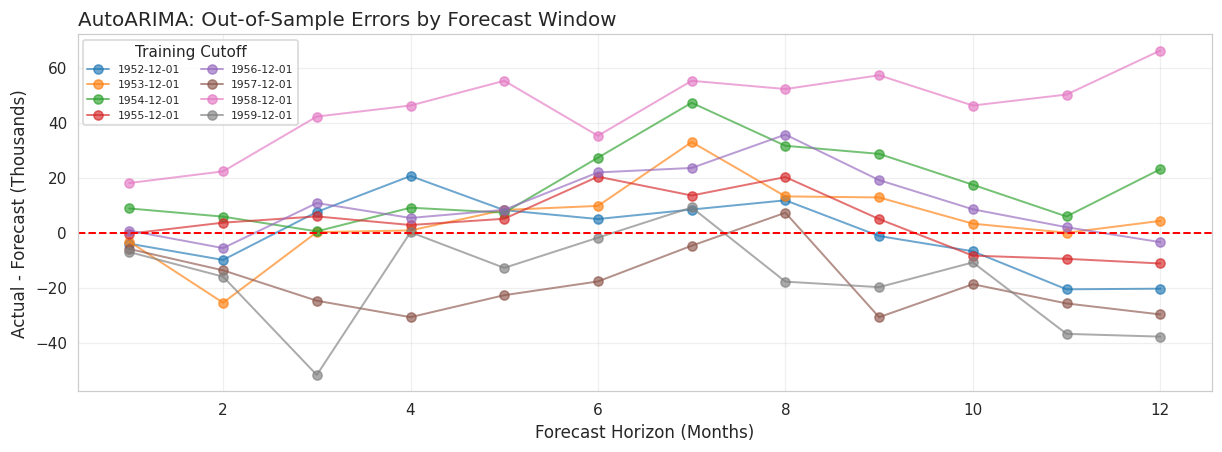

Mean error: 5.88
Mean absolute error: 17.74


In [23]:

# Calculate out-of-sample forecast errors
arima_errors = mycv.copy()

arima_errors["error"] = (
    arima_errors["y"] - arima_errors["AutoARIMA"]
)

# Show errors by forecast window
fig, ax = plt.subplots(figsize=(11, 4))

for cutoff, group in arima_errors.groupby("cutoff"):
    group = group.sort_values("ds")
    ax.plot(
        range(1, len(group) + 1),
        group["error"].to_numpy(),
        marker="o",
        alpha=0.65,
        label=str(cutoff)[:10]
    )

ax.axhline(0, color="red", linestyle="--")
ax.set_title("AutoARIMA: Out-of-Sample Errors by Forecast Window")
ax.set_xlabel("Forecast Horizon (Months)")
ax.set_ylabel("Actual - Forecast (Thousands)")
ax.legend(title="Training Cutoff", fontsize=7, ncol=2)
ax.grid(alpha=0.3)
plt.show()

# Summary statistics
print("Mean error:", round(arima_errors["error"].mean(), 2))
print("Mean absolute error:", round(arima_errors["error"].abs().mean(), 2))


**AutoARIMA Forecast Error Analysis**

The eight-window rolling-origin evaluation produced a mean forecast error of +5.88 thousand passengers and a mean absolute error of 17.74 thousand passengers. The positive mean error suggests that AutoARIMA slightly underestimates passenger demand on average.

Forecast errors vary substantially across validation windows. In particular, the window ending in December 1958 shows persistent positive errors, exceeding 60 thousand passengers at some forecast horizons, while other windows exhibit smaller or negative errors.

These patterns indicate that AutoARIMA captures the overall trend and seasonal structure more effectively than Seasonal Naive, but does not fully account for all changes in passenger demand. Further improvements should focus on interval calibration and the model's response to changing growth patterns.

**4.1 Read the table.** Does the harness confirm the leaderboard's
shortlist, or does it move it? For each model: where does it beat the
floor, where does it lose, and on which of the three metrics? A model that
wins the point forecast and loses the distribution is a real result -
report both halves. And what does each model's 80% coverage say about its
band?

---
# 5. The report

The notebook is evidence; the report is the claim. Two to three pages, for a
manager who will not open the notebook:

- **The recommendation.** Which model you would ship, in one sentence, and
  the one number that earns it.
- **The intervals.** How wide, what they covered, and whether the band is
  honest. Coverage is the check a band cannot do alone.
- **The residuals.** What the floor - and your model - missed. A residual
  ACF is a fact; a sentence about what it means is the deliverable.
- **One change.** A specific next step - data, driver, frequency, horizon -
  and what you expect it to do.

Rules: every number in the report comes out of this notebook; no number
that could not have come out of the harness counts; no leakage - a fold's
fit and its denominator use only data that fold was allowed to see.

**Optional, for extra credit.** The series is a total across origins, so a
driver is a modelling choice, not a lookup: pick a region and pull its
monthly mean temperature from a public weather archive (for example
Open-Meteo's historical API - free, no key), cache it next to the CSV, and
regress on it. That is dynamic regression - and the cross-validation
discipline still applies to the regression's residuals.